# TACS (Ours) - Stanford Cars, true validation split, DINOv3 ViT-B/16

This CAR notebook preserves the TACS full-candidate-pool ViT-B/16 structure from the source notebook and changes the dataset input to Stanford Cars: anno_train.csv, anno_test.csv, names.csv, and car_data. It stratifies 10% validation from official train; test remains the official test split.

The candidate pool is sampled from actual-train after validation split. Outputs/checkpoints use a separate CAR folder.

In [13]:
# from google.colab import drive
# drive.mount('/content/drive')

In [14]:
# !unzip -q /content/drive/MyDrive/archive\ \(13\).zip -d /content/archive\ \(13\)/

## 1. Offline environment

No package installation or model download is performed in this notebook. Kaggle must already provide PyTorch, torchvision, pandas, Pillow, tqdm, matplotlib, and scikit-learn.

In [15]:
import importlib.util
required = ["torch", "torchvision", "pandas", "PIL", "tqdm", "matplotlib", "sklearn"]
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(f"Missing packages in offline Kaggle environment: {missing}")
print("Dependencies available; no installation or Internet access used.")

Dependencies available; no installation or Internet access used.


## 2. Offline DINOv3 assets

Attach the DINOv3 source repo and ViT-B checkpoint `dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth` to Kaggle Input. The notebook loads the local repo with `torch.hub.load(..., source="local")`; it does not download the model.

Also attach the Stanford Cars dataset containing `anno_train.csv`, `anno_test.csv`, `names.csv`, and `car_data/`.

## 2. Imports, config, Stanford Cars, and candidate pool

Reads train/test from `anno_train.csv` and `anno_test.csv`; splits 10% stratified validation only from train. The 20% candidate pool is sampled from actual-train after validation split. Bounding boxes in annotations are used to crop each car image.

In [16]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

torch.backends.cudnn.benchmark = True
# Tận dụng Tensor Cores thế hệ mới trên dòng RTX / GPU Ampere+
torch.set_float32_matmul_precision('high')
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('DEVICE:', DEVICE)

# --- ĐƯỜNG DẪN OUTPUT (Ghi vào working của Kaggle) ---
PROJECT_DIR = Path('/kaggle/working')
OUT_PUT_DIR = PROJECT_DIR / 'outputs' / 'tacs_full_pool_car_true_val_split_b16'
OUTPUT_DIR = OUT_PUT_DIR
OUT_PUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Stanford Cars dataset paths ---
DATASET_ROOT_CANDIDATES = [
    Path('/kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder'),
    Path('/kaggle/input/datasets/hiuphmnhtrung/stanford-car-dataset-by-classes-folder'),
    Path('/kaggle/input/stanford-car-dataset-by-classes-folder'),
    Path('/kaggle/input/datasets/YOUR_USERNAME/stanford-car-dataset-by-classes-folder'),
    Path('/kaggle/input'),
]
for pattern in ('*', '*/*', 'datasets/*/*', 'datasets/*/*/*'):
    DATASET_ROOT_CANDIDATES.extend(Path('/kaggle/input').glob(pattern))
DATASET_ROOT = next(
    (p for p in DATASET_ROOT_CANDIDATES
     if (p / 'anno_train.csv').is_file()
     and (p / 'anno_test.csv').is_file()
     and (p / 'names.csv').is_file()),
    DATASET_ROOT_CANDIDATES[0],
)
if not all((DATASET_ROOT / name).is_file() for name in ('anno_train.csv', 'anno_test.csv', 'names.csv')):
    raise FileNotFoundError(f'Stanford Cars annotation files not found below {DATASET_ROOT}')
TRAIN_IMAGE_ROOT_CANDIDATES = [
    DATASET_ROOT / 'car_data' / 'car_data' / 'train',
    DATASET_ROOT / 'car_data' / 'train', DATASET_ROOT / 'train',
]
TEST_IMAGE_ROOT_CANDIDATES = [
    DATASET_ROOT / 'car_data' / 'car_data' / 'test',
    DATASET_ROOT / 'car_data' / 'test', DATASET_ROOT / 'test',
]
TRAIN_IMAGE_ROOT = next((p for p in TRAIN_IMAGE_ROOT_CANDIDATES if p.is_dir()), TRAIN_IMAGE_ROOT_CANDIDATES[0])
TEST_IMAGE_ROOT = next((p for p in TEST_IMAGE_ROOT_CANDIDATES if p.is_dir()), TEST_IMAGE_ROOT_CANDIDATES[0])
IMAGE_ROOT = DATASET_ROOT

DINOV3_REPO_DIR = '/kaggle/input/datasets/sinhnguync/dinov3-code/dinov3-main'
if not Path(DINOV3_REPO_DIR).exists():
    for p in [Path('/kaggle/input/dinov3-code/dinov3-main'), Path('/kaggle/input/dinov3-code')]:
        if p.exists():
            DINOV3_REPO_DIR = str(p)
            break

DINOV3_MODEL_NAME = 'dinov3_vitb16'
DINOV3_WEIGHTS = '/kaggle/input/datasets/sinhnguync/dinov3-vitb16/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth'
if not Path(DINOV3_WEIGHTS).exists():
    for p in [
        Path('/kaggle/input/datasets/sinhnguync/dinov3-vitb16/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth'),
        Path('/kaggle/input/dinov3-vitb16/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth'),
        Path('/kaggle/input/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth'),
    ]:
        if p.exists():
            DINOV3_WEIGHTS = str(p)
            break

BACKBONE_NAME = DINOV3_MODEL_NAME
FEATURE_DIM = 768

IMAGE_SIZE = 384
BATCH_SIZE = 32
EPOCHS = 100
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
BACKBONE_LR = 3e-6
HEAD_LR = 1e-4
BACKBONE_WEIGHT_DECAY = 0.05
HEAD_WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
TOKEN_HEAD_DROPOUT = 0.3
FREEZE_BACKBONE_EPOCHS = 0
WARMUP_EPOCHS = 5
PATIENCE = 10
GRAD_CLIP_NORM = 1.0
NUM_WORKERS = 8
NUM_CLASSES = 196  # Stanford Cars has 196 classes
TOP_K = 5
CONTEXT_TOP_K = 1
RETRIEVAL_SCORE_WEIGHT = 0.0
SUPCON_WEIGHT = 0.05
SUPCON_TEMPERATURE = 0.10
USE_BBOX_CROP = True  # Use the provided Stanford Cars bounding boxes
CANDIDATE_POOL_FRACTION = 0.20
VAL_FRACTION = 0.10
RETRIEVAL_BATCH_SIZE = 512
RETRIEVAL_CHUNK_SIZE = 4096
QUERY_CONTEXT_GATE_DROPOUT = 0.20
QUERY_CONTEXT_GATE_BIAS = -0.7
EVAL_TTA_HORIZONTAL_FLIP = False
USE_CONTEXT_LABEL_PRIOR = False
CONTEXT_LABEL_PRIOR_WEIGHT = 0.25
CONTEXT_LABEL_PRIOR_TEMPERATURE = 0.07

TRAIN_ON_FULL_TRAIN = False
FULL_TRAIN_MONITOR_FRACTION = 0.05  # chi dung khi TRAIN_ON_FULL_TRAIN=True

# --- TACS selector hyperparameters ---
TACS_CANDIDATES_PER_QUERY = None  # None nghĩa là dùng toàn bộ candidate pool
TACS_PREFILTER_TOP_SIMILAR = 0
TACS_GUMBEL_TAU = 0.10
TACS_POLICY_WEIGHT = 1.0
TACS_ENTROPY_WEIGHT = 0.01
TACS_SELECTOR_LR = 1e-4
TACS_SELECTOR_WEIGHT_DECAY = 1e-4
TACS_SELECTOR_DROPOUT = 0.10
TACS_SELECTOR_TEMPERATURE = 1.0

# --- Full-pool selector memory controls ---
TACS_USE_FULL_CANDIDATE_POOL = True
CANDIDATE_IMAGE_BANK_DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
CANDIDATE_IMAGE_BANK_DTYPE = torch.float16 if torch.cuda.is_available() else torch.float32
CANDIDATE_FEATURE_BANK_BATCH_SIZE = 128
FULL_POOL_SCORE_CHUNK_SIZE = 1024

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 48, IMAGE_SIZE + 48)),
    transforms.RandomResizedCrop(
        (IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.60, 1.0),
        ratio=(0.80, 1.25),
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.25,
            contrast=0.25,
            saturation=0.20,
            hue=0.04,
        )
    ], p=0.75),
    transforms.RandomGrayscale(p=0.05),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
    ], p=0.15),
    transforms.ToTensor(),
    transforms.RandomErasing(
        p=0.20,
        scale=(0.02, 0.12),
        ratio=(0.3, 3.3),
        value="random",
    ),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

_mean = globals().get("DINO_MEAN", globals().get("IMAGENET_MEAN", (0.485, 0.456, 0.406)))
_std = globals().get("DINO_STD", globals().get("IMAGENET_STD", (0.229, 0.224, 0.225)))

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=_mean, std=_std),
])


def load_class_names(dataset_root):
    names = pd.read_csv(dataset_root / 'names.csv', header=None)[0].astype(str).str.strip().tolist()
    if len(names) != 196:
        raise ValueError(f'Expected 196 class names, found {len(names)}')
    return names


def load_annotations(dataset_root, split):
    columns = ['fname', 'bbox_x1', 'bbox_y1', 'bbox_x2', 'bbox_y2', 'class_id_1based']
    path = dataset_root / f'anno_{split}.csv'
    df = pd.read_csv(path, header=None, names=columns)
    if not str(df.iloc[0]['class_id_1based']).strip().isdigit():
        df = df.iloc[1:].reset_index(drop=True)
    for col in ['bbox_x1', 'bbox_y1', 'bbox_x2', 'bbox_y2', 'class_id_1based']:
        df[col] = pd.to_numeric(df[col], errors='raise').astype(int)
    df['fname'] = df['fname'].astype(str).str.strip()
    df['class_id'] = df['class_id_1based'] - 1
    if not df['class_id'].between(0, 195).all():
        raise ValueError(f'Class IDs outside 1..196 in {path}')
    df['split'] = split
    df['row_id'] = np.arange(len(df))
    return df


def attach_image_paths(df, image_root):
    image_root = Path(image_root)
    if not image_root.is_dir():
        raise FileNotFoundError(f'Image directory not found: {image_root}')
    valid_exts = {'.jpg', '.jpeg', '.png'}
    image_index = {}
    for path in sorted(image_root.rglob('*')):
        if path.is_file() and path.suffix.lower() in valid_exts:
            if path.name in image_index:
                raise ValueError(f'Duplicate filename in {image_root}: {path.name}')
            image_index[path.name] = path
    missing = [fname for fname in df['fname'] if fname not in image_index]
    if missing:
        raise FileNotFoundError(f'Missing {len(missing)} images under {image_root}; examples: {missing[:5]}')
    out = df.copy()
    out['image_path'] = [str(image_index[fname].resolve()) for fname in out['fname']]
    return out


def split_train_val_by_class(df, val_fraction=0.10, seed=42):
    if not 0 < val_fraction < 1:
        raise ValueError('val_fraction must be between 0 and 1')
    rng = np.random.default_rng(seed)
    val_indices = []
    for _, group in df.groupby('class_id', sort=True):
        indices = group.index.to_numpy()
        if len(indices) <= 1:
            continue
        n_val = min(max(1, int(round(len(indices) * val_fraction))), len(indices) - 1)
        val_indices.extend(rng.choice(indices, size=n_val, replace=False).tolist())
    val_indices = np.asarray(sorted(val_indices), dtype=int)
    return df.drop(index=val_indices).reset_index(drop=True), df.loc[val_indices].reset_index(drop=True)


class_names = load_class_names(DATASET_ROOT)
full_train_df = attach_image_paths(load_annotations(DATASET_ROOT, 'train'), TRAIN_IMAGE_ROOT).reset_index(drop=True)
test_df = attach_image_paths(load_annotations(DATASET_ROOT, 'test'), TEST_IMAGE_ROOT).reset_index(drop=True)
NUM_CLASSES = len(class_names)
train_df, val_df = split_train_val_by_class(full_train_df, VAL_FRACTION, SEED)
if TRAIN_ON_FULL_TRAIN:
    _, monitor_val_df = split_train_val_by_class(full_train_df, FULL_TRAIN_MONITOR_FRACTION, SEED)
    train_df = full_train_df.reset_index(drop=True)
    val_df = monitor_val_df.reset_index(drop=True)

candidate_rng = np.random.default_rng(SEED)
if CANDIDATE_POOL_FRACTION >= 1.0:
    candidate_pool_positions = np.arange(len(train_df), dtype=int)
else:
    candidate_pool_size = max(1, int(round(len(train_df) * CANDIDATE_POOL_FRACTION)))
    candidate_pool_positions = np.sort(
        candidate_rng.choice(len(train_df), size=candidate_pool_size, replace=False)
    )

candidate_df = train_df.iloc[candidate_pool_positions].reset_index(drop=True)
candidate_df.to_csv(OUT_PUT_DIR / 'candidate_pool.csv', index=False)
val_df.to_csv(OUT_PUT_DIR / 'validation_split.csv', index=False)

print('DATASET_ROOT:', DATASET_ROOT.resolve())
print('TRAIN_IMAGE_ROOT:', TRAIN_IMAGE_ROOT.resolve())
print('TEST_IMAGE_ROOT:', TEST_IMAGE_ROOT.resolve())
print('OUT_PUT_DIR:', OUT_PUT_DIR.resolve())
print(f'Standard train images: {len(full_train_df):,}')
print(f'Actual train images: {len(train_df):,}')
print(f'Validation images: {len(val_df):,}')
print(f'Train on full train: {TRAIN_ON_FULL_TRAIN}')
print(f'Standard test images: {len(test_df):,}')
print(f'Candidate pool: {len(candidate_df):,}/{len(train_df):,} actual-train images ({CANDIDATE_POOL_FRACTION:.0%})')
print(f'TACS selected context per query: {CONTEXT_TOP_K}')
print(f'TACS uses full candidate pool during training: {TACS_USE_FULL_CANDIDATE_POOL}')
print(f'TACS Gumbel tau: {TACS_GUMBEL_TAU}, policy weight: {TACS_POLICY_WEIGHT}')
print(f'BBox crop enabled: {USE_BBOX_CROP}')
print(f'Train label range: {int(train_df.class_id.min())}..{int(train_df.class_id.max())}')
print(f'Test label range: {int(test_df.class_id.min())}..{int(test_df.class_id.max())}')
display(train_df.head())
display(val_df.head())
display(candidate_df.head())

DEVICE: cuda
DATASET_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder
TRAIN_IMAGE_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data/train
TEST_IMAGE_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data/test
OUT_PUT_DIR: /kaggle/working/outputs/tacs_full_pool_car_true_val_split_b16
Standard train images: 8,144
Actual train images: 7,356
Validation images: 788
Train on full train: False
Standard test images: 8,041
Candidate pool: 1,471/7,356 actual-train images (20%)
TACS selected context per query: 1
TACS uses full candidate pool during training: True
TACS Gumbel tau: 0.1, policy weight: 1.0
BBox crop enabled: True
Train label range: 0..195
Test label range: 0..195


,fname,bbox_x1,bbox_y1,bbox_x2,bbox_y2,class_id_1based,class_id,split,row_id,image_path
0,00001.jpg,39,116,569,375,14,13,train,0,/kaggle/input/datasets/jutrera/stanford-car-da...
1,00002.jpg,36,116,868,587,3,2,train,1,/kaggle/input/datasets/jutrera/stanford-car-da...
2,00003.jpg,85,109,601,381,91,90,train,2,/kaggle/input/datasets/jutrera/stanford-car-da...
3,00004.jpg,621,393,1484,1096,134,133,train,3,/kaggle/input/datasets/jutrera/stanford-car-da...
4,00005.jpg,14,36,133,99,106,105,train,4,/kaggle/input/datasets/jutrera/stanford-car-da...


,fname,bbox_x1,bbox_y1,bbox_x2,bbox_y2,class_id_1based,class_id,split,row_id,image_path
0,00031.jpg,55,318,446,564,154,153,train,30,/kaggle/input/datasets/jutrera/stanford-car-da...
1,00045.jpg,12,108,489,297,186,185,train,44,/kaggle/input/datasets/jutrera/stanford-car-da...
2,00046.jpg,28,80,759,466,25,24,train,45,/kaggle/input/datasets/jutrera/stanford-car-da...
3,00048.jpg,142,69,753,451,177,176,train,47,/kaggle/input/datasets/jutrera/stanford-car-da...
4,00057.jpg,260,138,972,439,44,43,train,56,/kaggle/input/datasets/jutrera/stanford-car-da...


,fname,bbox_x1,bbox_y1,bbox_x2,bbox_y2,class_id_1based,class_id,split,row_id,image_path
0,00012.jpg,6,62,499,286,186,185,train,11,/kaggle/input/datasets/jutrera/stanford-car-da...
1,00030.jpg,82,109,874,521,194,193,train,29,/kaggle/input/datasets/jutrera/stanford-car-da...
2,00034.jpg,37,63,614,397,133,132,train,33,/kaggle/input/datasets/jutrera/stanford-car-da...
3,00035.jpg,223,87,1111,670,154,153,train,34,/kaggle/input/datasets/jutrera/stanford-car-da...
4,00038.jpg,16,89,459,326,97,96,train,37,/kaggle/input/datasets/jutrera/stanford-car-da...


## 3. Dataset và DataLoader

Với full candidate pool, train dataset chỉ cần trả về query image và label. Candidate images được cache riêng trong candidate image bank; selector sẽ tính score với toàn bộ candidate pool trong train loop.


In [17]:
class SimpleImageDataset(Dataset):
    def __init__(self, annotations, transform, crop_bbox=False):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.transform = transform
        self.crop_bbox = crop_bbox

    def __len__(self):
        return len(self.annotations)

    def _open_image(self, row):
        image = Image.open(row['image_path']).convert('RGB')
        if self.crop_bbox:
            left = max(0, int(row['bbox_x1']) - 1)
            top = max(0, int(row['bbox_y1']) - 1)
            right = min(image.width, max(left + 1, int(row['bbox_x2'])))
            bottom = min(image.height, max(top + 1, int(row['bbox_y2'])))
            image = image.crop((left, top, right, bottom))
        return image

    def __getitem__(self, index):
        row = self.annotations.iloc[index]
        image = self.transform(self._open_image(row))
        return image, int(index), row['fname'], int(row['class_id'])


class StanfordCarsSimilarityContextDataset(Dataset):
    def __init__(self, annotations, candidate_annotations, context_positions, context_scores, query_transform, context_transform, crop_bbox=False):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.candidate_annotations = candidate_annotations.reset_index(drop=True).copy()
        self.context_positions = np.asarray(context_positions, dtype=np.int64)
        self.context_scores = np.asarray(context_scores, dtype=np.float32)
        if self.context_positions.ndim == 1:
            self.context_positions = self.context_positions[:, None]
        if self.context_scores.ndim == 1:
            self.context_scores = self.context_scores[:, None]
        self.query_transform = query_transform
        self.context_transform = context_transform
        self.crop_bbox = crop_bbox
        if len(self.context_positions) != len(self.annotations):
            raise ValueError('context_positions phai co cung do dai voi annotations')
        if len(self.context_scores) != len(self.annotations):
            raise ValueError('context_scores phai co cung do dai voi annotations')

    def __len__(self):
        return len(self.annotations)

    def set_epoch(self, epoch):
        pass

    def _open_image(self, row):
        image = Image.open(row['image_path']).convert('RGB')
        if self.crop_bbox:
            left = max(0, int(row['bbox_x1']) - 1)
            top = max(0, int(row['bbox_y1']) - 1)
            right = min(image.width, max(left + 1, int(row['bbox_x2'])))
            bottom = min(image.height, max(top + 1, int(row['bbox_y2'])))
            image = image.crop((left, top, right, bottom))
        return image

    def __getitem__(self, index):
        query_row = self.annotations.iloc[index]
        context_positions = self.context_positions[index]
        context_scores = self.context_scores[index]
        context_rows = [self.candidate_annotations.iloc[int(pos)] for pos in context_positions]
        query_image = self.query_transform(self._open_image(query_row))
        context_images = torch.stack([self.context_transform(self._open_image(context_row)) for context_row in context_rows], dim=0)
        context_labels = torch.tensor([int(context_row['class_id']) for context_row in context_rows], dtype=torch.long)
        return {
            'query_image': query_image,
            'context_images': context_images,
            'label': torch.tensor(int(query_row['class_id']), dtype=torch.long),
            'fname': query_row['fname'],
            'context_fnames': '|'.join(str(context_row['fname']) for context_row in context_rows),
            "context_labels": torch.tensor(context_labels, dtype=torch.long),
            'context_scores': torch.as_tensor(context_scores, dtype=torch.float32),
        }




class StanfordCarsTACSQueryDataset(Dataset):
    def __init__(self, annotations, transform, crop_bbox=False):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.transform = transform
        self.crop_bbox = crop_bbox

    def __len__(self):
        return len(self.annotations)

    def _open_image(self, row):
        image = Image.open(row['image_path']).convert('RGB')
        if self.crop_bbox:
            left = max(0, int(row['bbox_x1']) - 1)
            top = max(0, int(row['bbox_y1']) - 1)
            right = min(image.width, max(left + 1, int(row['bbox_x2'])))
            bottom = min(image.height, max(top + 1, int(row['bbox_y2'])))
            image = image.crop((left, top, right, bottom))
        return image

    def __getitem__(self, index):
        row = self.annotations.iloc[index]
        return {
            'query_image': self.transform(self._open_image(row)),
            'label': torch.tensor(int(row['class_id']), dtype=torch.long),
            'fname': row['fname'],
            'row_id': torch.tensor(int(row['row_id']), dtype=torch.long),
        }


## 4. TACS selector và downstream model

Selector encode query images bằng DINOv3 backbone đang huấn luyện. Candidate pool được encode thành feature bank theo từng epoch bằng chính backbone hiện tại. Sau đó mỗi query tính score với **toàn bộ** candidate feature bank.

Training chọn context bằng straight-through Gumbel-Softmax trên full pool: forward là một ảnh context hard-selected, backward vẫn cho gradient từ classification loss đi qua selector. Policy loss vẫn được giữ để học reward như TACS.


In [18]:
from pathlib import Path
import gc
import torch


def resolve_dinov3_weights():
    path = Path(DINOV3_WEIGHTS)
    if not path.is_file():
        raise FileNotFoundError(f'Không tìm thấy file weight: {path}')
    return str(path)


def load_dinov3_model(repo_dir, model_name, weights_path):
    repo_dir = Path(repo_dir)
    if not repo_dir.is_dir():
        raise FileNotFoundError(f'Không tìm thấy thư mục mã nguồn: {repo_dir}')
    weights_path = Path(weights_path)
    if not weights_path.is_file():
        raise FileNotFoundError(f'Không tìm thấy file weight: {weights_path}')
    return torch.hub.load(str(repo_dir), model_name, source='local', weights=str(weights_path))


def load_dinov3_backbone():
    return load_dinov3_model(DINOV3_REPO_DIR, DINOV3_MODEL_NAME, resolve_dinov3_weights())


def ensure_dinov3_assets():
    resolve_dinov3_weights()
    repo_dir = Path(DINOV3_REPO_DIR)
    if not repo_dir.is_dir():
        raise FileNotFoundError(f'Không tìm thấy thư mục mã nguồn: {repo_dir}')
    print('DINOv3 assets đã sẵn sàng từ Kaggle Input.')


def extract_cls_features(backbone, images):
    features = backbone(images)
    if isinstance(features, dict):
        if 'x_norm_clstoken' in features:
            return features['x_norm_clstoken']
        if 'x_norm_cls_token' in features:
            return features['x_norm_cls_token']
        if 'x_norm_patchtokens' in features:
            return features['x_norm_patchtokens'].mean(dim=1)
        raise KeyError(f'Khong tim thay CLS token trong output keys: {list(features)}')
    return features[:, 0] if torch.is_tensor(features) and features.ndim == 3 else features


def extract_frozen_dino_embeddings(annotations, backbone, desc):
    dataset = SimpleImageDataset(annotations, eval_transform, crop_bbox=USE_BBOX_CROP)
    loader = DataLoader(dataset, batch_size=RETRIEVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True,persistent_workers=True if NUM_WORKERS > 0 else False)
    embeddings = []
    backbone.eval()
    for parameter in backbone.parameters():
        parameter.requires_grad_(False)
    with torch.inference_mode():
        for images, *_ in tqdm(loader, desc=desc, leave=False):
            images = images.to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):
                features = extract_cls_features(backbone, images)
            features = F.normalize(features.float(), dim=1)
            embeddings.append(features.cpu())
    return torch.cat(embeddings, dim=0)




class DinoV3FrozenSimilarityContextClassifier(nn.Module):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=768, allow_feature_fallback=False):
        super().__init__()
        self.backbone = load_dinov3_model(repo_dir, model_name, weights_path)
        self.feature_dim = feature_dim
        self.allow_feature_fallback = allow_feature_fallback
        self.active_fusion_mode = 'topk_token_attention'
        self.context_proj = nn.Linear(feature_dim, feature_dim)
        self.query_proj = nn.Linear(feature_dim, feature_dim)
        self.context_attention = nn.Linear(feature_dim, 1)
        self.fusion_norm = nn.LayerNorm(feature_dim)
        self.token_head = nn.Sequential(nn.Dropout(p=TOKEN_HEAD_DROPOUT), nn.Linear(feature_dim, num_classes))
        self.feature_fusion = nn.Sequential(nn.Linear(feature_dim * 2, feature_dim), nn.GELU(), nn.Dropout(p=TOKEN_HEAD_DROPOUT), nn.Linear(feature_dim, num_classes))
        for param in self.backbone.parameters():
            param.requires_grad_(False)

    def _prefix_token_count(self):
        if hasattr(self.backbone, 'num_prefix_tokens'):
            return int(self.backbone.num_prefix_tokens)
        storage_tokens = getattr(self.backbone, 'n_storage_tokens', None)
        if storage_tokens is None:
            storage_tokens = getattr(self.backbone, 'num_register_tokens', 0)
        return 1 + int(storage_tokens or 0)

    def _patch_grid(self, images):
        patch_size = getattr(self.backbone, 'patch_size', 16)
        if isinstance(patch_size, (tuple, list)):
            patch_h, patch_w = int(patch_size[0]), int(patch_size[1])
        else:
            patch_h = patch_w = int(patch_size)
        return images.shape[-2] // patch_h, images.shape[-1] // patch_w

    def _unwrap_tokens(self, prepared):
        if torch.is_tensor(prepared):
            return prepared
        if isinstance(prepared, (tuple, list)):
            for item in prepared:
                if torch.is_tensor(item):
                    return item
        if isinstance(prepared, dict):
            for key in ('x', 'tokens', 'last_hidden_state'):
                if key in prepared and torch.is_tensor(prepared[key]):
                    return prepared[key]
            for item in prepared.values():
                if torch.is_tensor(item):
                    return item
        raise TypeError(f'Cannot unwrap DINO token output of type {type(prepared)}')

    def _prepare_tokens_with_rope(self, images):
        try:
            prepared = self.backbone.prepare_tokens_with_masks(images, None)
        except TypeError:
            prepared = self.backbone.prepare_tokens_with_masks(images)
        tokens = self._unwrap_tokens(prepared)
        rope = None
        if hasattr(self.backbone, 'rope_embed'):
            grid_h, grid_w = self._patch_grid(images)
            try:
                rope = self.backbone.rope_embed(H=grid_h, W=grid_w)
            except TypeError:
                rope = self.backbone.rope_embed(grid_h, grid_w)
        return tokens, rope

    def _repeat_rope_for_query_context(self, rope):
        if rope is None or not torch.is_tensor(rope):
            return rope
        try:
            return rope.repeat_interleave(2, dim=-2)
        except RuntimeError:
            return rope

    def _run_blocks(self, tokens, rope):
        for block in self.backbone.blocks:
            if rope is None:
                tokens = block(tokens)
                continue
            try:
                tokens = block(tokens, rope=rope)
            except TypeError:
                try:
                    tokens = block(tokens, rope)
                except TypeError:
                    tokens = block(tokens)
        if hasattr(self.backbone, 'norm'):
            tokens = self.backbone.norm(tokens)
        return tokens

    def _forward_token_concat_features(self, query_images, context_images):
        query_tokens, query_rope = self._prepare_tokens_with_rope(query_images)
        context_tokens, _ = self._prepare_tokens_with_rope(context_images)
        prefix_tokens = self._prefix_token_count()
        pair_tokens = torch.cat([query_tokens[:, :prefix_tokens], query_tokens[:, prefix_tokens:], context_tokens[:, prefix_tokens:]], dim=1)
        pair_rope = self._repeat_rope_for_query_context(query_rope)
        pair_tokens = self._run_blocks(pair_tokens, pair_rope)
        return pair_tokens[:, 0]

    def _pool_backbone_features(self, images):
        features = self.backbone.forward_features(images)
        if isinstance(features, dict):
            if 'x_norm_clstoken' in features:
                return features['x_norm_clstoken']
            if 'x_norm_patchtokens' in features:
                return features['x_norm_patchtokens'].mean(dim=1)
            for item in features.values():
                if torch.is_tensor(item):
                    return item[:, 0] if item.ndim == 3 else item
        if torch.is_tensor(features):
            return features[:, 0] if features.ndim == 3 else features
        raise TypeError(f'Cannot pool DINO features of type {type(features)}')

    def _forward_feature_fusion(self, query_images, context_images):
        if context_images.ndim == 5:
            context_images = context_images[:, 0]
        query_features = self._pool_backbone_features(query_images)
        context_features = self._pool_backbone_features(context_images)
        self.active_fusion_mode = 'feature_fusion'
        return self.feature_fusion(torch.cat([query_features, context_features], dim=1))

    def _forward_topk_token_attention(self, query_images, context_images, context_scores=None):
        if context_images.ndim == 4:
            context_images = context_images.unsqueeze(1)
        batch_size, num_contexts, channels, height, width = context_images.shape
        query_repeated = query_images.unsqueeze(1).expand(-1, num_contexts, -1, -1, -1).reshape(batch_size * num_contexts, channels, height, width)
        context_flat = context_images.reshape(batch_size * num_contexts, channels, height, width)
        pair_features = self._forward_token_concat_features(query_repeated, context_flat).reshape(batch_size, num_contexts, self.feature_dim)
        query_summary = pair_features.mean(dim=1)
        attention_hidden = torch.tanh(self.context_proj(pair_features) + self.query_proj(query_summary).unsqueeze(1))
        attention_logits = self.context_attention(attention_hidden).squeeze(-1)
        if context_scores is not None:
            if context_scores.ndim == 1:
                context_scores = context_scores.unsqueeze(1)
            attention_logits = attention_logits + RETRIEVAL_SCORE_WEIGHT * context_scores.to(attention_logits.device, dtype=attention_logits.dtype)
        attention_weights = torch.softmax(attention_logits, dim=1)
        fused_features = torch.sum(pair_features * attention_weights.unsqueeze(-1), dim=1)
        fused_features = self.fusion_norm(fused_features)
        self.active_fusion_mode = 'topk_token_attention'
        return fused_features, attention_weights

    def forward(self, query_images, context_images, context_scores=None, return_features=False):
        try:
            fused_features, attention_weights = self._forward_topk_token_attention(query_images, context_images, context_scores=context_scores)
            logits = self.token_head(fused_features)
            if return_features:
                return logits, F.normalize(fused_features.float(), dim=1), attention_weights
            return logits
        except Exception as exc:
            if self.allow_feature_fallback:
                print(f'Top-k token attention failed, fallback to feature fusion: {type(exc).__name__}: {exc}')
                logits = self._forward_feature_fusion(query_images, context_images)
                if return_features:
                    return logits, F.normalize(logits.float(), dim=1), None
                return logits
            raise RuntimeError('Top-k token attention failed. Keep allow_feature_fallback=False for debugging.') from exc

class DinoV3GatedTopKContextClassifier(DinoV3FrozenSimilarityContextClassifier):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=768, allow_feature_fallback=False):
        super().__init__(
            repo_dir=repo_dir,
            model_name=model_name,
            weights_path=weights_path,
            num_classes=num_classes,
            feature_dim=feature_dim,
            allow_feature_fallback=allow_feature_fallback,
        )
        self.query_norm = nn.LayerNorm(feature_dim)
        self.context_norm = nn.LayerNorm(feature_dim)
        self.final_norm = nn.LayerNorm(feature_dim)

        self.query_head = nn.Sequential(
            nn.Dropout(p=TOKEN_HEAD_DROPOUT),
            nn.Linear(feature_dim, num_classes),
        )

        self.fusion_gate = nn.Sequential(
            nn.Linear(feature_dim * 4, feature_dim),
            nn.GELU(),
            nn.Dropout(p=QUERY_CONTEXT_GATE_DROPOUT),
            nn.Linear(feature_dim, 1),
        )
        nn.init.constant_(self.fusion_gate[-1].bias, QUERY_CONTEXT_GATE_BIAS)
        self.active_fusion_mode = "query_plus_gated_topk_context"

    def forward(self, query_images, context_images, context_scores=None, return_features=False):
        try:
            context_features, attention_weights = self._forward_topk_token_attention(
                query_images,
                context_images,
                context_scores=context_scores,
            )
            query_features = self._pool_backbone_features(query_images)

            query_features = self.query_norm(query_features)
            context_features = self.context_norm(context_features)

            gate_input = torch.cat(
                [
                    query_features,
                    context_features,
                    query_features * context_features,
                    torch.abs(query_features - context_features),
                ],
                dim=1,
            )
            gate = torch.sigmoid(self.fusion_gate(gate_input))

            query_logits = self.query_head(query_features)
            context_logits = self.token_head(context_features)
            logits = query_logits + gate * context_logits

            fused_features = self.final_norm(query_features + gate * context_features)
            self.active_fusion_mode = "query_plus_gated_topk_context"

            if return_features:
                return logits, F.normalize(fused_features.float(), dim=1), attention_weights
            return logits

        except Exception as exc:
            if self.allow_feature_fallback:
                print(f"Gated fusion failed, fallback to parent model: {type(exc).__name__}: {exc}")
                return super().forward(query_images, context_images, context_scores=context_scores, return_features=return_features)
            raise




class TACSSelector(nn.Module):
    def __init__(self, temperature=1.0, normalize=True):
        super().__init__()
        self.temperature = float(temperature)
        self.normalize = bool(normalize)
        self.logit_scale = nn.Parameter(torch.tensor(1.0))

    def score(self, query_features, candidate_features):
        query = query_features.float()
        candidates = candidate_features.float()
        if self.normalize:
            query = F.normalize(query, dim=-1)
            candidates = F.normalize(candidates, dim=-1)
        scores = query @ candidates.T
        return scores * self.logit_scale.clamp(0.01, 100.0) / max(self.temperature, 1e-6)


class DinoV3TACSClassifier(DinoV3GatedTopKContextClassifier):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=768, allow_feature_fallback=False):
        super().__init__(
            repo_dir=repo_dir,
            model_name=model_name,
            weights_path=weights_path,
            num_classes=num_classes,
            feature_dim=feature_dim,
            allow_feature_fallback=allow_feature_fallback,
        )
        self.selector = TACSSelector(
            temperature=TACS_SELECTOR_TEMPERATURE,
            normalize=True,
        )
        self.active_fusion_mode = 'tacs_full_pool_shared_backbone_selector'

    def selector_encode_images(self, images):
        return self._pool_backbone_features(images)

    def score_full_candidate_pool(self, query_images, candidate_feature_bank):
        query_features = self.selector_encode_images(query_images)
        selector_scores = self.selector.score(query_features, candidate_feature_bank.to(query_features.device))
        return selector_scores, query_features

    def select_full_pool(self, query_images, candidate_feature_bank, use_gumbel=True):
        selector_scores, query_features = self.score_full_candidate_pool(query_images, candidate_feature_bank)
        if self.training and use_gumbel:
            selection_weights = F.gumbel_softmax(
                selector_scores,
                tau=TACS_GUMBEL_TAU,
                hard=True,
                dim=1,
            )
            selected_indices = selection_weights.argmax(dim=1)
        else:
            selected_indices = selector_scores.argmax(dim=1)
            selection_weights = F.one_hot(selected_indices, num_classes=selector_scores.size(1)).to(selector_scores.dtype)
        details = {
            'selector_scores': selector_scores,
            'selection_weights': selection_weights,
            'selected_indices': selected_indices,
            'query_features': query_features,
            'selector_entropy': torch.distributions.Categorical(logits=selector_scores.float()).entropy().mean(),
        }
        self.active_fusion_mode = 'tacs_full_pool_shared_backbone_selector'
        return details

    def forward_selected_context(self, query_images, selected_context_images, return_features=False):
        context_images = selected_context_images.unsqueeze(1)
        return super().forward(query_images, context_images, context_scores=None, return_features=return_features)

    def forward_query_only(self, query_images):
        query_features = self._pool_backbone_features(query_images)
        if hasattr(self, 'query_norm') and hasattr(self, 'query_head'):
            query_features = self.query_norm(query_features)
            return self.query_head(query_features)
        return self.token_head(query_features)


def build_candidate_image_bank(annotations, transform, device, dtype):
    dataset = SimpleImageDataset(annotations, transform, crop_bbox=USE_BBOX_CROP)
    loader = DataLoader(dataset, batch_size=RETRIEVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    images_bank = []
    labels = []
    fnames = []
    for images, labels_batch, fnames_batch, *_ in tqdm(loader, desc='build candidate image bank', leave=False):
        images_bank.append(images.to(device=device, dtype=dtype, non_blocking=True).contiguous())
        labels.extend([int(x) for x in labels_batch.tolist()])
        fnames.extend(fnames_batch)
    return torch.cat(images_bank, dim=0), torch.tensor(labels, dtype=torch.long, device=device), fnames


@torch.no_grad()
def refresh_candidate_feature_bank(network, candidate_image_bank, batch_size=CANDIDATE_FEATURE_BANK_BATCH_SIZE):
    was_training = network.training
    network.eval()
    features = []
    with torch.inference_mode():
        for start in tqdm(range(0, len(candidate_image_bank), batch_size), desc='refresh full candidate feature bank', leave=False):
            end = min(start + batch_size, len(candidate_image_bank))
            images = candidate_image_bank[start:end].to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):
                feats = network.selector_encode_images(images)
            features.append(feats.float().detach().cpu())
    if was_training:
        network.train()
    return torch.cat(features, dim=0)


ensure_dinov3_assets()

train_dataset = StanfordCarsTACSQueryDataset(train_df, train_transform, crop_bbox=USE_BBOX_CROP)
val_dataset = StanfordCarsTACSQueryDataset(val_df, eval_transform, crop_bbox=USE_BBOX_CROP)
test_dataset = StanfordCarsTACSQueryDataset(test_df, eval_transform, crop_bbox=USE_BBOX_CROP)

loader_kwargs = {'num_workers': NUM_WORKERS, 'pin_memory': torch.cuda.is_available()}
if NUM_WORKERS > 0:
    loader_kwargs['persistent_workers'] = True
    loader_kwargs['prefetch_factor'] = 2

train_generator = torch.Generator()
train_generator.manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=train_generator, **loader_kwargs)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

model = DinoV3TACSClassifier(
    DINOV3_REPO_DIR,
    DINOV3_MODEL_NAME,
    resolve_dinov3_weights(),
    NUM_CLASSES,
    FEATURE_DIM,
    allow_feature_fallback=False,
).to(DEVICE)

candidate_image_bank, candidate_labels_tensor, candidate_fnames = build_candidate_image_bank(
    candidate_df,
    eval_transform,
    device=torch.device(CANDIDATE_IMAGE_BANK_DEVICE),
    dtype=CANDIDATE_IMAGE_BANK_DTYPE,
)

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
backbone_params = [p for name, p in model.named_parameters() if name.startswith('backbone.')]
selector_params = [p for name, p in model.named_parameters() if name.startswith('selector.')]
head_params = [p for name, p in model.named_parameters() if not name.startswith('backbone.') and not name.startswith('selector.')]
optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': BACKBONE_LR, 'weight_decay': BACKBONE_WEIGHT_DECAY, 'name': 'backbone'},
    {'params': selector_params, 'lr': TACS_SELECTOR_LR, 'weight_decay': TACS_SELECTOR_WEIGHT_DECAY, 'name': 'selector'},
    {'params': head_params, 'lr': HEAD_LR, 'weight_decay': HEAD_WEIGHT_DECAY, 'name': 'head'},
])

warmup_epochs = max(1, min(WARMUP_EPOCHS, EPOCHS))
main_epochs = max(1, EPOCHS - warmup_epochs)
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.2, end_factor=1.0, total_iters=warmup_epochs)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=main_epochs, eta_min=1e-7)
scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_epochs])
scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == 'cuda')

checkpoint_path = OUT_PUT_DIR / 'final_tacs_full_pool_dinov3_vitb16_stanford_cars.pt'
last_checkpoint_path = OUT_PUT_DIR / 'checkpoint_last.pt'
best_checkpoint_path = OUT_PUT_DIR / 'best_val_checkpoint.pt'

torch.save({
    'candidate_pool_positions': torch.as_tensor(candidate_pool_positions, dtype=torch.long),
    'seed': SEED,
    'candidate_pool_fraction': CANDIDATE_POOL_FRACTION,
    'use_bbox_crop': USE_BBOX_CROP,
    'selector_mode': 'full_candidate_pool_shared_backbone',
    'candidate_image_bank_device': CANDIDATE_IMAGE_BANK_DEVICE,
    'candidate_image_bank_dtype': str(CANDIDATE_IMAGE_BANK_DTYPE),
}, OUT_PUT_DIR / 'tacs_selector_cache.pt')

sample = train_dataset[0]
print('Saved TACS selector cache:', (OUT_PUT_DIR / 'tacs_selector_cache.pt').resolve())
print('Candidate image bank:', candidate_image_bank.shape, candidate_image_bank.device, candidate_image_bank.dtype)
print('Sample query tensor:', sample['query_image'].shape)
print('Candidate pool size used per query:', len(candidate_df))
print('Initial fusion mode:', model.active_fusion_mode)
print(model)


DINOv3 assets đã sẵn sàng từ Kaggle Input.


build candidate image bank:   0%|          | 0/3 [00:00<?, ?it/s]

Saved TACS selector cache: /kaggle/working/outputs/tacs_full_pool_car_true_val_split_b16/tacs_selector_cache.pt
Candidate image bank: torch.Size([1471, 3, 384, 384]) cuda:0 torch.float16
Sample query tensor: torch.Size([3, 384, 384])
Candidate pool size used per query: 1471
Initial fusion mode: tacs_full_pool_shared_backbone_selector
DinoV3TACSClassifier(
  (backbone): DinoVisionTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      (norm): Identity()
    )
    (rope_embed): RopePositionEmbedding()
    (blocks): ModuleList(
      (0-11): 12 x SelfAttentionBlock(
        (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): SelfAttention(
          (qkv): LinearKMaskedBias(in_features=768, out_features=2304, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=768, out_features=768, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
       

/tmp/ipykernel_163/1129068045.py:446: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == 'cuda')


## 5. Train TACS full candidate pool và lưu checkpoint

Mỗi epoch refresh candidate feature bank bằng backbone hiện tại. Trong từng batch, selector tính score giữa query và toàn bộ candidate pool, chọn context bằng Gumbel/policy, rồi downstream classifier học trên cặp query-context đã chọn.


In [19]:
from sklearn.metrics import f1_score


def macro_f1_from_predictions(labels, predictions):
    return float(f1_score(labels, predictions, average='macro', zero_division=0))


def supervised_contrastive_loss(features, labels, temperature=0.10):
    features = F.normalize(features.float(), dim=1)
    labels = labels.view(-1, 1)
    mask = torch.eq(labels, labels.T).float().to(features.device)
    logits = torch.matmul(features, features.T) / temperature
    logits = logits - logits.max(dim=1, keepdim=True).values.detach()
    logits_mask = torch.ones_like(mask) - torch.eye(mask.size(0), device=features.device)
    positives_mask = mask * logits_mask
    positive_counts = positives_mask.sum(dim=1)
    valid = positive_counts > 0
    if not torch.any(valid):
        return features.sum() * 0.0
    exp_logits = torch.exp(logits) * logits_mask
    log_prob = logits - torch.log(exp_logits.sum(dim=1, keepdim=True).clamp_min(1e-12))
    mean_log_prob_pos = (positives_mask * log_prob).sum(dim=1) / positive_counts.clamp_min(1.0)
    return -mean_log_prob_pos[valid].mean()


def set_backbone_trainable(network, trainable):
    for name, param in network.named_parameters():
        if name.startswith('backbone.'):
            param.requires_grad_(trainable)
    if hasattr(network, 'backbone'):
        network.backbone.train(mode=trainable)


def current_lrs(opt):
    return {group.get('name', f'group_{index}'): group['lr'] for index, group in enumerate(opt.param_groups)}


def move_query_batch_to_device(batch):
    return {
        'query_images': batch['query_image'].to(DEVICE, non_blocking=True),
        'labels': batch['label'].to(DEVICE, non_blocking=True),
        'fname': batch['fname'],
    }


def add_context_label_prior(logits, context_labels, context_scores):
    if not USE_CONTEXT_LABEL_PRIOR:
        return logits
    if context_labels.ndim == 1:
        context_labels = context_labels.unsqueeze(1)
    if context_scores.ndim == 1:
        context_scores = context_scores.unsqueeze(1)
    weights = torch.softmax(context_scores / CONTEXT_LABEL_PRIOR_TEMPERATURE, dim=1)
    prior_logits = torch.zeros_like(logits)
    prior_logits.scatter_add_(dim=1, index=context_labels.long(), src=weights.to(logits.dtype))
    return logits + CONTEXT_LABEL_PRIOR_WEIGHT * prior_logits


def gather_bank_images(indices):
    return candidate_image_bank[indices.detach().to(candidate_image_bank.device)].to(DEVICE, non_blocking=True).float()


def select_bank_images_from_weights(selection_weights):
    """Straight-through selected context.

    F.gumbel_softmax(..., hard=True) has one-hot forward values but soft gradients.
    Multiplying by the full image bank keeps the forward context equal to one real
    candidate image while allowing L_grad to update the selector, as in TACS.
    """
    bank = candidate_image_bank.to(DEVICE, non_blocking=True)
    bank_flat = bank.flatten(1)
    weights = selection_weights.to(device=bank_flat.device, dtype=bank_flat.dtype)
    selected_flat = weights @ bank_flat
    return selected_flat.view(weights.size(0), *bank.shape[1:]).float()


def gather_bank_labels(indices):
    return candidate_labels_tensor[indices.detach().to(candidate_labels_tensor.device)].to(DEVICE, non_blocking=True)


def train_one_epoch(network, loader, epoch, candidate_feature_bank, backbone_trainable=True):
    network.train()
    set_backbone_trainable(network, backbone_trainable)
    candidate_feature_bank_device = candidate_feature_bank.to(DEVICE, non_blocking=True)
    running_loss = running_ce_loss = running_supcon_loss = 0.0
    running_policy_loss = running_reward = running_entropy = 0.0
    running_selected_same = running_correct = running_total = 0
    all_predictions, all_labels = [], []
    progress = tqdm(loader, desc=f'Epoch {epoch:03d} [train full-pool]', leave=False)

    for batch in progress:
        moved = move_query_batch_to_device(batch)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):
            details = network.select_full_pool(
                moved['query_images'],
                candidate_feature_bank_device,
                use_gumbel=True,
            )
            selected_context_images = select_bank_images_from_weights(details['selection_weights'])
            logits, features, _attention = network.forward_selected_context(
                moved['query_images'],
                selected_context_images,
                return_features=True,
            )
            ce_loss = criterion(logits, moved['labels'])
            supcon_loss = supervised_contrastive_loss(features, moved['labels'], temperature=SUPCON_TEMPERATURE)

            selector_scores = details['selector_scores'].float()
            policy_dist = torch.distributions.Categorical(logits=selector_scores)
            policy_actions = policy_dist.sample()
            log_probs = policy_dist.log_prob(policy_actions)
            entropy = policy_dist.entropy().mean()

            with torch.no_grad():
                query_only_logits = network.forward_query_only(moved['query_images'])
                policy_context_images = gather_bank_images(policy_actions)
                policy_context_logits = network.forward_selected_context(
                    moved['query_images'],
                    policy_context_images,
                    return_features=False,
                )
                query_losses = F.cross_entropy(query_only_logits.float(), moved['labels'], reduction='none')
                context_losses = F.cross_entropy(policy_context_logits.float(), moved['labels'], reduction='none')
                rewards = (query_losses - context_losses).detach()
                reward_std = rewards.std(unbiased=False).clamp_min(1e-6)
                advantages = ((rewards - rewards.mean()) / reward_std).detach()

            policy_loss = -(log_probs * advantages).mean()
            loss = ce_loss + SUPCON_WEIGHT * supcon_loss + TACS_POLICY_WEIGHT * policy_loss - TACS_ENTROPY_WEIGHT * entropy

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(network.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()

        predictions = logits.argmax(dim=1)
        batch_size = moved['labels'].size(0)
        selected_labels = gather_bank_labels(details['selected_indices'])
        running_selected_same += (selected_labels == moved['labels']).sum().item()
        running_correct += (predictions == moved['labels']).sum().item()
        running_total += batch_size
        running_loss += loss.item() * batch_size
        running_ce_loss += ce_loss.item() * batch_size
        running_supcon_loss += supcon_loss.item() * batch_size
        running_policy_loss += policy_loss.item() * batch_size
        running_reward += rewards.mean().item() * batch_size
        running_entropy += entropy.item() * batch_size
        all_predictions.extend(predictions.detach().cpu().tolist())
        all_labels.extend(moved['labels'].detach().cpu().tolist())
        progress.set_postfix(loss=running_loss / max(running_total, 1), acc=running_correct / max(running_total, 1))

    return {
        'loss': running_loss / max(running_total, 1),
        'ce_loss': running_ce_loss / max(running_total, 1),
        'supcon_loss': running_supcon_loss / max(running_total, 1),
        'policy_loss': running_policy_loss / max(running_total, 1),
        'reward': running_reward / max(running_total, 1),
        'selector_entropy': running_entropy / max(running_total, 1),
        'accuracy': running_correct / max(running_total, 1),
        'macro_f1': macro_f1_from_predictions(all_labels, all_predictions),
        'selected_same_class_rate': running_selected_same / max(running_total, 1),
    }


@torch.no_grad()
def evaluate_one_epoch(network, loader, candidate_feature_bank, desc='val'):
    network.eval()
    candidate_feature_bank_device = candidate_feature_bank.to(DEVICE, non_blocking=True)
    running_loss = running_correct = running_total = 0
    running_selected_same = running_entropy = 0.0
    all_predictions, all_labels = [], []
    for batch in tqdm(loader, desc=desc, leave=False):
        moved = move_query_batch_to_device(batch)
        with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):
            details = network.select_full_pool(
                moved['query_images'],
                candidate_feature_bank_device,
                use_gumbel=False,
            )
            selected_context_images = gather_bank_images(details['selected_indices'])
            logits = network.forward_selected_context(
                moved['query_images'],
                selected_context_images,
                return_features=False,
            )
            loss = criterion(logits, moved['labels'])
        predictions = logits.argmax(dim=1)
        batch_size = moved['labels'].size(0)
        selected_labels = gather_bank_labels(details['selected_indices'])
        running_selected_same += (selected_labels == moved['labels']).sum().item()
        running_entropy += details['selector_entropy'].item() * batch_size
        running_loss += loss.item() * batch_size
        running_correct += (predictions == moved['labels']).sum().item()
        running_total += batch_size
        all_predictions.extend(predictions.detach().cpu().tolist())
        all_labels.extend(moved['labels'].detach().cpu().tolist())
    return {
        'loss': running_loss / max(running_total, 1),
        'accuracy': running_correct / max(running_total, 1),
        'macro_f1': macro_f1_from_predictions(all_labels, all_predictions),
        'selected_same_class_rate': running_selected_same / max(running_total, 1),
        'selector_entropy': running_entropy / max(running_total, 1),
    }


def build_checkpoint_payload(epoch, train_metrics, val_metrics, best_val_loss, best_epoch, history):
    return {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'class_names': class_names,
        'metrics': {
            'train_loss': train_metrics['loss'],
            'train_ce_loss': train_metrics.get('ce_loss'),
            'train_supcon_loss': train_metrics.get('supcon_loss'),
            'train_policy_loss': train_metrics.get('policy_loss'),
            'train_reward': train_metrics.get('reward'),
            'train_selector_entropy': train_metrics.get('selector_entropy'),
            'train_selected_same_class_rate': train_metrics.get('selected_same_class_rate'),
            'train_accuracy': train_metrics['accuracy'],
            'train_macro_f1': train_metrics['macro_f1'],
            'val_loss': val_metrics['loss'],
            'val_accuracy': val_metrics['accuracy'],
            'val_macro_f1': val_metrics['macro_f1'],
            'val_selected_same_class_rate': val_metrics.get('selected_same_class_rate'),
            'val_selector_entropy': val_metrics.get('selector_entropy'),
            'best_val_loss': best_val_loss,
            'best_epoch': best_epoch,
        },
        'history': history,
        'config': {
            'dataset_root': str(DATASET_ROOT),
            'method': 'TACS',
            'selector_mode': 'full_candidate_pool_shared_backbone',
            'epochs': EPOCHS,
            'batch_size': BATCH_SIZE,
            'backbone_lr': BACKBONE_LR,
            'head_lr': HEAD_LR,
            'selector_lr': TACS_SELECTOR_LR,
            'candidate_pool_fraction': CANDIDATE_POOL_FRACTION,
            'candidate_pool_size': len(candidate_df),
            'tacs_use_full_candidate_pool': TACS_USE_FULL_CANDIDATE_POOL,
            'tacs_gumbel_tau': TACS_GUMBEL_TAU,
            'tacs_policy_weight': TACS_POLICY_WEIGHT,
            'tacs_entropy_weight': TACS_ENTROPY_WEIGHT,
            'supcon_weight': SUPCON_WEIGHT,
            'use_bbox_crop': USE_BBOX_CROP,
            'image_size': IMAGE_SIZE,
            'dino_model': DINOV3_MODEL_NAME,
            'feature_dim': FEATURE_DIM,
            'use_context_label_prior': USE_CONTEXT_LABEL_PRIOR,
            'fusion_mode': getattr(model, 'active_fusion_mode', 'unknown'),
        },
    }


RESUME_FROM_LAST_CHECKPOINT = False
history = []
start_epoch = 1
best_val_loss = float('inf')
best_epoch = 0
bad_epochs = 0

if RESUME_FROM_LAST_CHECKPOINT and last_checkpoint_path.is_file():
    checkpoint = torch.load(last_checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    scaler.load_state_dict(checkpoint['scaler_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    history = checkpoint.get('history', [])
    metrics = checkpoint.get('metrics', {})
    best_val_loss = metrics.get('best_val_loss', min((row.get('val_loss', float('inf')) for row in history), default=float('inf')))
    best_epoch = metrics.get('best_epoch', 0)
    print(f'Resuming from epoch {start_epoch}')

for epoch in range(start_epoch, EPOCHS + 1):
    backbone_trainable = epoch > FREEZE_BACKBONE_EPOCHS
    candidate_feature_bank = refresh_candidate_feature_bank(model, candidate_image_bank)
    train_metrics = train_one_epoch(model, train_loader, epoch, candidate_feature_bank, backbone_trainable=backbone_trainable)
    val_metrics = evaluate_one_epoch(model, val_loader, candidate_feature_bank, desc=f'Epoch {epoch:03d} [val full-pool]')
    scheduler.step()
    is_best = val_metrics['loss'] < best_val_loss - 1e-6
    if is_best:
        best_val_loss, best_epoch, bad_epochs = val_metrics['loss'], epoch, 0
    else:
        bad_epochs += 1
    lr_values = current_lrs(optimizer)
    record = {
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'train_ce_loss': train_metrics.get('ce_loss'),
        'train_supcon_loss': train_metrics.get('supcon_loss'),
        'train_policy_loss': train_metrics.get('policy_loss'),
        'train_reward': train_metrics.get('reward'),
        'train_selector_entropy': train_metrics.get('selector_entropy'),
        'train_selected_same_class_rate': train_metrics.get('selected_same_class_rate'),
        'train_accuracy': train_metrics['accuracy'],
        'train_macro_f1': train_metrics['macro_f1'],
        'val_loss': val_metrics['loss'],
        'val_accuracy': val_metrics['accuracy'],
        'val_macro_f1': val_metrics['macro_f1'],
        'val_selected_same_class_rate': val_metrics.get('selected_same_class_rate'),
        'val_selector_entropy': val_metrics.get('selector_entropy'),
        'best_val_loss': best_val_loss,
        'best_epoch': best_epoch,
        'bad_epochs': bad_epochs,
        'backbone_trainable': backbone_trainable,
        'backbone_lr': lr_values.get('backbone'),
        'selector_lr': lr_values.get('selector'),
        'head_lr': lr_values.get('head'),
        'fusion_mode': getattr(model, 'active_fusion_mode', 'unknown'),
    }
    history.append(record)
    payload = build_checkpoint_payload(epoch, train_metrics, val_metrics, best_val_loss, best_epoch, history)
    torch.save(payload, last_checkpoint_path)
    if is_best:
        torch.save(payload, best_checkpoint_path)
    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"train_loss={train_metrics['loss']:.4f} ce={train_metrics.get('ce_loss', 0):.4f} "
        f"policy={train_metrics.get('policy_loss', 0):.4f} reward={train_metrics.get('reward', 0):.4f} "
        f"train_acc={train_metrics['accuracy']:.4f} train_f1={train_metrics['macro_f1']:.4f} "
        f"sel_same={train_metrics.get('selected_same_class_rate', 0):.4f} | "
        f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} "
        f"val_f1={val_metrics['macro_f1']:.4f} val_sel_same={val_metrics.get('selected_same_class_rate', 0):.4f} | "
        f"best_val={best_val_loss:.4f}@{best_epoch:03d} bad={bad_epochs}/{PATIENCE} | "
        f"bb_train={backbone_trainable} bb_lr={lr_values.get('backbone'):.2e} "
        f"sel_lr={lr_values.get('selector'):.2e} head_lr={lr_values.get('head'):.2e}"
    )
    if bad_epochs >= PATIENCE:
        print(f'Early stopping at epoch {epoch}; best validation loss was {best_val_loss:.4f} at epoch {best_epoch}.')
        break

final_train_metrics = train_metrics
final_val_metrics = val_metrics
final_payload = build_checkpoint_payload(epoch, final_train_metrics, final_val_metrics, best_val_loss, best_epoch, history)
torch.save(final_payload, checkpoint_path)
print('Saved final checkpoint to:', checkpoint_path.resolve())
if best_checkpoint_path.is_file():
    print('Saved best validation checkpoint to:', best_checkpoint_path.resolve())
history_df = pd.DataFrame(history)
history_df.to_csv(OUT_PUT_DIR / 'training_history.csv', index=False)
display(history_df.tail())


refresh full candidate feature bank:   0%|          | 0/12 [00:00<?, ?it/s]

/tmp/ipykernel_163/1129068045.py:390: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


Epoch 001 [train full-pool]:   0%|          | 0/230 [00:00<?, ?it/s]

/tmp/ipykernel_163/3771650659.py:94: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


Epoch 001 [val full-pool]:   0%|          | 0/25 [00:00<?, ?it/s]

/tmp/ipykernel_163/3771650659.py:176: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


... (289 outputs left out)

/tmp/ipykernel_163/1129068045.py:390: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


Epoch 043 [train full-pool]:   0%|          | 0/230 [00:00<?, ?it/s]

/tmp/ipykernel_163/3771650659.py:94: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


KeyboardInterrupt: 

## 6. Vẽ training history

Dùng để kiểm tra loss/accuracy trong quá trình train. Benchmark chính nằm ở cell `Official test accuracy`.


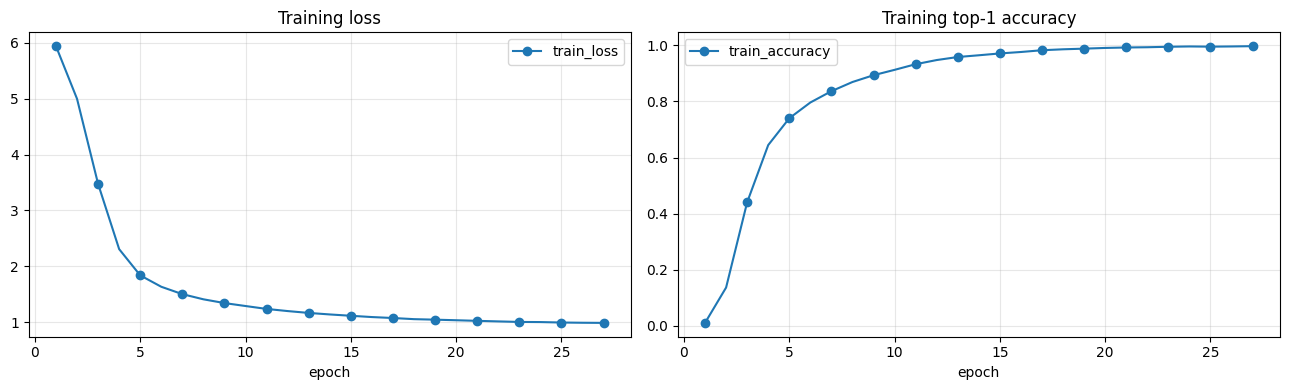

,epoch,train_loss,train_ce_loss,train_supcon_loss,train_policy_loss,train_reward,train_selector_entropy,train_selected_same_class_rate,train_accuracy,train_macro_f1,...,val_selected_same_class_rate,val_selector_entropy,best_val_loss,best_epoch,bad_epochs,backbone_trainable,backbone_lr,selector_lr,head_lr,fusion_mode
22,23,1.002984,1.061062,0.467605,0.000328,0.661168,8.178561,0.000392,0.994906,0.994903,...,0.0,8.178577,1.579951,17,6,True,0.000003,0.000091,0.000091,query_plus_gated_topk_context
23,24,1.000518,1.054956,0.518366,0.001430,0.643329,8.178591,0.000168,0.996026,0.996014,...,0.0,8.178608,1.579951,17,7,True,0.000003,0.000090,0.000090,query_plus_gated_topk_context
24,25,0.992586,1.050071,0.508393,-0.001118,0.643125,8.178567,0.000336,0.995298,0.995298,...,0.0,8.178558,1.579951,17,8,True,0.000003,0.000089,0.000089,query_plus_gated_topk_context
25,26,0.988314,1.045963,0.489760,-0.000351,0.625103,8.178529,0.000504,0.996026,0.996020,...,0.0,8.178527,1.579951,17,9,True,0.000003,0.000088,0.000088,query_plus_gated_topk_context
26,27,0.985979,1.041765,0.499277,0.001036,0.619178,8.178521,0.000168,0.997033,0.997030,...,0.0,8.178531,1.579951,17,10,True,0.000003,0.000087,0.000087,query_plus_gated_topk_context


In [20]:
import pandas as pd
if 'history_df' not in globals():
    history_df = pd.read_csv(OUT_PUT_DIR / 'training_history.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
history_df.plot(x='epoch', y='train_loss', ax=axes[0], marker='o', markevery=max(1, len(history_df) // 10), title='Training loss')
history_df.plot(x='epoch', y='train_accuracy', ax=axes[1], marker='o', markevery=max(1, len(history_df) // 10), title='Training top-1 accuracy')
for axis in axes:
    axis.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
display(history_df.tail())


## 7. Official test accuracy

Cell này load best checkpoint, refresh candidate feature bank bằng backbone đã train, rồi dùng selector chọn context từ toàn bộ candidate pool 20% cho từng test query.


## 8. Inference và load checkpoint

Dùng hàm này để test nhanh một ảnh. Nếu không truyền context thủ công, selector TACS sẽ chọn context có utility score cao nhất từ candidate pool.


In [21]:



import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

def macro_f1_score_np(y_true, y_pred, num_classes):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    f1_values = []
    for class_id in range(num_classes):
        tp = np.sum((y_true == class_id) & (y_pred == class_id))
        fp = np.sum((y_true != class_id) & (y_pred == class_id))
        fn = np.sum((y_true == class_id) & (y_pred != class_id))
        denom = 2 * tp + fp + fn
        f1_values.append(0.0 if denom == 0 else float((2 * tp) / denom))
    return float(np.mean(f1_values))

@torch.no_grad()
def evaluate_full_pool_context_model(network, loader, candidate_feature_bank, top_k=TOP_K):
    network.eval()
    candidate_feature_bank_device = candidate_feature_bank.to(DEVICE, non_blocking=True)
    total_loss = 0.0
    all_targets, all_predictions, rows = [], [], []
    top_k = min(top_k, NUM_CLASSES)

    def get_class_name(cid):
        return class_names[cid] if 0 <= cid < len(class_names) else f"class_{cid}"

    with torch.inference_mode():
        for batch in tqdm(loader, desc='test full-pool', leave=False):
            moved = move_query_batch_to_device(batch)
            with torch.amp.autocast('cuda', enabled=DEVICE.type == 'cuda'):
                details = network.select_full_pool(
                    moved['query_images'],
                    candidate_feature_bank_device,
                    use_gumbel=False,
                )
                selected_context_images = gather_bank_images(details['selected_indices'])
                logits = network.forward_selected_context(
                    moved['query_images'],
                    selected_context_images,
                    return_features=False,
                )
                loss = criterion(logits, moved['labels'])

            probs = torch.softmax(logits, dim=1).cpu()
            values, indices = torch.topk(probs, k=top_k, dim=1)
            predictions = logits.argmax(dim=1).detach().cpu()
            labels_cpu = moved['labels'].detach().cpu()
            selected_indices_cpu = details['selected_indices'].detach().cpu()
            selected_scores_cpu = details['selector_scores'].gather(
                1, details['selected_indices'].view(-1, 1)
            ).squeeze(1).detach().cpu()

            total_loss += loss.item() * moved['query_images'].size(0)
            all_targets.extend(labels_cpu.tolist())
            all_predictions.extend(predictions.tolist())

            for row_index, (fname, label, pred, value_row, index_row) in enumerate(
                zip(batch['fname'], labels_cpu, predictions, values, indices)
            ):
                label_id = int(label)
                pred_id = int(pred)
                context_pool_pos = int(selected_indices_cpu[row_index])
                
                # Lấy trực tiếp thông tin từ candidate_df để tránh lỗi index
                context_row = candidate_df.iloc[context_pool_pos]
                context_label_id = int(context_row['class_id'])
                context_fname = str(context_row['fname'])
                
                top_class_ids = [int(index) for index in index_row]
                true_name = get_class_name(label_id)
                pred_name = get_class_name(pred_id)
                context_name = get_class_name(context_label_id)

                rows.append({
                    'fname': fname,
                    'true_class_id': label_id,
                    'true_car_name': true_name,
                    'context_fnames': context_fname,
                    'context_class_ids': str(context_label_id),
                    'context_car_names': context_name,
                    'top1_context_fname': context_fname,
                    'top1_context_class_id': context_label_id,
                    'top1_context_car_name': context_name,
                    'top1_context_pool_position': context_pool_pos,
                    'top1_tacs_score': float(selected_scores_cpu[row_index]),
                    'same_class_context_top1': bool(label_id == context_label_id),
                    'same_class_context_any_topk': bool(label_id == context_label_id),
                    'same_class_context': bool(label_id == context_label_id),
                    'predicted_class_id': pred_id,
                    'predicted_car_name': pred_name,
                    'correct': bool(pred_id == label_id),
                    'confidence': float(value_row[0]),
                    'top_k_class_ids': '|'.join(str(index) for index in top_class_ids),
                })

    avg_loss = total_loss / len(loader.dataset)
    acc = float(np.mean([r['correct'] for r in rows])) if rows else 0.0
    macro_f1 = macro_f1_score_np(all_targets, all_predictions, NUM_CLASSES)
    same_context_rate = float(np.mean([r['same_class_context_top1'] for r in rows])) if rows else 0.0

    return {
        'loss': avg_loss,
        'accuracy': acc,
        'macro_f1': macro_f1,
        'test_context_top1_same_class_rate': same_context_rate,
        'predictions': pd.DataFrame(rows),
    }

# 1. Nạp checkpoint tốt nhất để đánh giá
eval_checkpoint_path = best_checkpoint_path if best_checkpoint_path.is_file() else checkpoint_path
print('Loaded checkpoint for evaluation:', eval_checkpoint_path.resolve())
checkpoint = torch.load(eval_checkpoint_path, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(DEVICE)
model.eval()

# 2. Ensure class_names matches the 196 Stanford Cars classes
if 'class_names' not in globals() or len(class_names) != NUM_CLASSES:
    class_names = load_class_names(DATASET_ROOT)

# 3. Làm mới candidate feature bank bằng backbone đã huấn luyện
candidate_feature_bank = refresh_candidate_feature_bank(model, candidate_image_bank)
torch.save({
    'candidate_feature_bank': candidate_feature_bank.cpu(),
    'candidate_labels': candidate_labels_tensor.cpu(),
    'candidate_fnames': candidate_fnames,
}, OUT_PUT_DIR / 'trained_tacs_full_pool_candidate_feature_bank.pt')

# 4. Đánh giá mô hình trên toàn bộ tập test
results = evaluate_full_pool_context_model(model, test_loader, candidate_feature_bank, top_k=TOP_K)
test_prediction_df = results.pop('predictions')
test_prediction_df.to_csv(OUT_PUT_DIR / 'test_predictions.csv', index=False)

metrics = results
print(f"test_loss: {metrics['loss']:.4f}")
print(f"test_accuracy: {metrics['accuracy']:.4f}")
print(f"test_macro_f1: {metrics['macro_f1']:.4f}")
if 'test_context_top1_same_class_rate' in metrics:
    print(f"top1_same_class_tacs_context_rate: {metrics['test_context_top1_same_class_rate']:.4f}")

display(test_prediction_df.head())

Loaded checkpoint for evaluation: /kaggle/working/outputs/tacs_full_pool_car_true_val_split_b16/best_val_checkpoint.pt


refresh full candidate feature bank:   0%|          | 0/12 [00:00<?, ?it/s]

/tmp/ipykernel_163/1129068045.py:390: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


test full-pool:   0%|          | 0/252 [00:00<?, ?it/s]

test_loss: 1.0705
test_accuracy: 0.9515
test_macro_f1: 0.9503
top1_same_class_tacs_context_rate: 0.9095


,fname,true_class_id,true_car_name,context_fnames,context_class_ids,context_car_names,top1_context_fname,top1_context_class_id,top1_context_car_name,top1_context_pool_position,top1_tacs_score,same_class_context_top1,same_class_context_any_topk,same_class_context,predicted_class_id,predicted_car_name,correct,confidence,top_k_class_ids
0,00001.jpg,180,Suzuki Aerio Sedan 2007,04228.jpg,180,Suzuki Aerio Sedan 2007,04228.jpg,180,Suzuki Aerio Sedan 2007,750,0.842285,True,True,True,180,Suzuki Aerio Sedan 2007,True,0.957031,180|70|68|43|30
1,00002.jpg,102,Ferrari 458 Italia Convertible 2012,04844.jpg,102,Ferrari 458 Italia Convertible 2012,04844.jpg,102,Ferrari 458 Italia Convertible 2012,864,0.829102,True,True,True,102,Ferrari 458 Italia Convertible 2012,True,0.958496,102|101|54|135|103
2,00003.jpg,144,Jeep Patriot SUV 2012,00718.jpg,144,Jeep Patriot SUV 2012,00718.jpg,144,Jeep Patriot SUV 2012,124,0.812500,True,True,True,144,Jeep Patriot SUV 2012,True,0.913574,144|148|145|146|153
3,00004.jpg,186,Toyota Camry Sedan 2012,05387.jpg,186,Toyota Camry Sedan 2012,05387.jpg,186,Toyota Camry Sedan 2012,980,0.833496,True,True,True,186,Toyota Camry Sedan 2012,True,0.923340,186|133|187|109|15
4,00005.jpg,184,Tesla Model S Sedan 2012,07728.jpg,184,Tesla Model S Sedan 2012,07728.jpg,184,Tesla Model S Sedan 2012,1398,0.824219,True,True,True,184,Tesla Model S Sedan 2012,True,0.940430,184|166|179|129|133


In [22]:
@torch.no_grad()
def find_tacs_contexts_for_image(image_path, top_k=CONTEXT_TOP_K):
    image_path = Path(image_path)
    image = eval_transform(Image.open(image_path).convert('RGB')).unsqueeze(0).to(DEVICE)
    model.eval()
    if 'candidate_feature_bank' not in globals():
        globals()['candidate_feature_bank'] = refresh_candidate_feature_bank(model, candidate_image_bank)
    with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):
        details = model.select_full_pool(image, candidate_feature_bank.to(DEVICE), use_gumbel=False)
    values, positions = torch.topk(details['selector_scores'].detach().cpu(), k=min(top_k, len(candidate_df)), dim=1)
    context_rows = [candidate_df.iloc[int(pos)] for pos in positions[0].tolist()]
    return context_rows, [float(score) for score in values[0].tolist()]


def load_tacs_model_for_inference(checkpoint_file, device=DEVICE):
    saved = torch.load(checkpoint_file, map_location=device)
    loaded_model = DinoV3TACSClassifier(
        repo_dir=DINOV3_REPO_DIR,
        model_name=DINOV3_MODEL_NAME,
        weights_path=resolve_dinov3_weights(),
        num_classes=len(saved['class_names']),
        feature_dim=FEATURE_DIM,
        allow_feature_fallback=False,
    )
    loaded_model.load_state_dict(saved['model_state_dict'])
    return loaded_model.to(device).eval(), saved['class_names']


model, class_names = load_tacs_model_for_inference(best_checkpoint_path)


def predict_one_image_with_tacs_context(image_path, context_image_paths=None, network=model, top_k=TOP_K):
    if network is None:
        network = model
    image_path = Path(image_path)
    if context_image_paths is None:
        context_rows, tacs_scores = find_tacs_contexts_for_image(image_path, top_k=CONTEXT_TOP_K)
        context_image_paths = [Path(row['image_path']) for row in context_rows]
        context_names = [class_names[int(row['class_id'])] for row in context_rows]
        context_labels = [int(row['class_id']) for row in context_rows]
    else:
        if isinstance(context_image_paths, (str, Path)):
            context_image_paths = [context_image_paths]
        context_image_paths = [Path(path) for path in context_image_paths]
        context_names = [None] * len(context_image_paths)
        context_labels = [0] * len(context_image_paths)
        tacs_scores = [0.0] * len(context_image_paths)

    query_image = eval_transform(Image.open(image_path).convert('RGB')).unsqueeze(0).to(DEVICE)
    context_images = torch.stack([eval_transform(Image.open(path).convert('RGB')) for path in context_image_paths], dim=0).unsqueeze(0).to(DEVICE)
    context_scores = torch.tensor([tacs_scores], dtype=torch.float32, device=DEVICE)
    context_labels_tensor = torch.tensor([context_labels], dtype=torch.long, device=DEVICE)

    network.eval()
    with torch.inference_mode():
        logits = predict_logits_with_tta(network, query_image, context_images, context_scores, context_labels_tensor)
        probs = torch.softmax(logits, dim=1)[0]
        values, indices = torch.topk(probs, k=min(top_k, NUM_CLASSES))

    print('Query:', image_path)
    for rank, (context_path, context_name, tacs_score) in enumerate(zip(context_image_paths, context_names, tacs_scores), start=1):
        print(f'TACS context {rank}:', context_path)
        if context_name is not None:
            print(f'  label: {context_name}')
        print(f'  TACS utility score: {tacs_score:.4f}')
    print('\nTop predictions:')
    for rank, (class_id, probability) in enumerate(zip(indices.tolist(), values.tolist()), start=1):
        print(f'{rank}. {class_names[class_id]} | p={probability:.4f}')


print('Final checkpoint:', checkpoint_path.resolve())
print('Best-val checkpoint:', best_checkpoint_path.resolve())
print('Latest checkpoint:', last_checkpoint_path.resolve())
print('Method:', 'TACS (Ours) - full candidate pool shared-backbone selector')


Final checkpoint: /kaggle/working/outputs/tacs_full_pool_car_true_val_split_b16/final_tacs_full_pool_dinov3_vitb16_stanford_cars.pt
Best-val checkpoint: /kaggle/working/outputs/tacs_full_pool_car_true_val_split_b16/best_val_checkpoint.pt
Latest checkpoint: /kaggle/working/outputs/tacs_full_pool_car_true_val_split_b16/checkpoint_last.pt
Method: TACS (Ours) - full candidate pool shared-backbone selector


In [23]:
import torch
import gc

gc.collect()
torch.cuda.empty_cache()

## 9. Ghi chú benchmark

- Method này là bản **TACS full candidate pool**: mỗi query tính utility score với toàn bộ candidate pool 20%.
- Candidate pool lấy **20% train split**, đúng Candidate Pool Construction trong paper.
- Training dùng straight-through Gumbel-Softmax (`TACS_GUMBEL_TAU=0.10`) và policy reward `loss_query_only - loss_with_context`.
- Để tránh OOM, notebook cache candidate images và refresh candidate feature bank theo epoch/chunk. Không tạo tensor `[batch, pool, C, H, W]`.
- `BATCH_SIZE=8` để an toàn trên RTX Pro 6000; nếu VRAM còn rộng có thể thử 12 hoặc 16.
- `CANDIDATE_FEATURE_BANK_BATCH_SIZE=128`; nếu VRAM còn rộng có thể tăng 256 để refresh bank nhanh hơn.
- `USE_CONTEXT_LABEL_PRIOR=False`: không dùng nhãn context để cộng logits.
- Metric chính cho SUN là `test_accuracy`; nên theo dõi thêm `top1_same_class_tacs_context_rate`, `train_reward`, `train_policy_loss`, và `selector_entropy`.


In [24]:
# import numpy as np
# import pandas as pd
# from PIL import Image
# from tqdm import tqdm

# def analyze_dataset_dimensions(df, check_bbox=True):
#     widths, heights = [], []
#     crop_w_list, crop_h_list = [], []

#     for _, row in tqdm(df.iterrows(), total=len(df), desc="Đang quét kích thước ảnh"):
#         # Image.open chỉ đọc metadata header, cực nhanh và không tốn RAM
#         with Image.open(row['image_path']) as img:
#             w, h = img.size
#             widths.append(w)
#             heights.append(h)

#         if check_bbox and 'bbox_x1' in row:
#             left = max(0, int(row['bbox_x1']) - 1)
#             top = max(0, int(row['bbox_y1']) - 1)
#             right = max(left + 1, int(row['bbox_x2']))
#             bottom = max(top + 1, int(row['bbox_y2']))
#             crop_w_list.append(right - left)
#             crop_h_list.append(bottom - top)

#     data = {
#         "Metric": ["Min", "Max", "Mean", "Median"],
#         "Orig Width (W)": [np.min(widths), np.max(widths), round(np.mean(widths), 1), np.median(widths)],
#         "Orig Height (H)": [np.min(heights), np.max(heights), round(np.mean(heights), 1), np.median(heights)],
#     }

#     if check_bbox and crop_w_list:
#         data["Crop Width (BBox)"] = [np.min(crop_w_list), np.max(crop_w_list), round(np.mean(crop_w_list), 1), np.median(crop_w_list)]
#         data["Crop Height (BBox)"] = [np.min(crop_h_list), np.max(crop_h_list), round(np.mean(crop_h_list), 1), np.median(crop_h_list)]

#     stats_df = pd.DataFrame(data)
    
#     # Tính tỉ lệ khung hình (Aspect Ratio W/H)
#     aspect_ratios = np.array(widths) / np.array(heights)
#     print(f"Aspect ratio gốc trung bình (W/H): {aspect_ratios.mean():.2f}")
#     print(f"Số ảnh có W > H (ảnh ngang): {np.sum(aspect_ratios > 1.0)} / {len(df)} ({np.mean(aspect_ratios > 1.0):.1%})")
    
#     return stats_df

# # Kiểm tra trên tập train
# train_size_stats = analyze_dataset_dimensions(full_train_df, check_bbox=USE_BBOX_CROP)
# display(train_size_stats)